### Dataset Features

In [71]:
import pandas as pd

contestant_dataset = pd.read_csv('contestant_dataset.csv')

# print(contestant_dataset.columns)
# print(len(contestant_dataset))

### Directional Wave Spectrum Metadata

First get convention metadata for the first sample. To be confirmed with Miros:
* Heading seas is 0° and following seas is 180°.
* Angular reference for wave spectrum is anchored to true North, i.e., "direction relative to 2."

In [72]:
import json

first_sample = json.loads(contestant_dataset['Wave directional spectrum'].iloc[0])

print(f"Direction count: {first_sample['DirectionCount']}")
print(f"Direction start: {first_sample['DirectionStart']}")
print(f"Direction relative to: {first_sample['DirectionRelativeTo']}")
print(f"Direction convention: {first_sample['DirectionConvention']}")
print(f"Heading (varies per sample): {first_sample['Heading']}")

Direction count: 36
Direction start: 0.0
Direction relative to: 2
Direction convention: 0
Heading (varies per sample): 141.0


Then run a sanity check to confirm wave spectrum conventions are consistent through the entire dataset.

In [73]:
mask = contestant_dataset['Wave directional spectrum'].apply(
    lambda s: json.loads(s)["DirectionCount"] == first_sample["DirectionCount"] and
              json.loads(s)["DirectionStart"] == first_sample["DirectionStart"] and
              json.loads(s)["DirectionRelativeTo"] == first_sample["DirectionRelativeTo"] and
              json.loads(s)["DirectionConvention"] == first_sample["DirectionConvention"]
)

if len(contestant_dataset[mask]) == len(contestant_dataset):
        print("All rows match metadata from first sample.")

All rows match metadata from first sample.


### Directional Wave Spectrum Plot

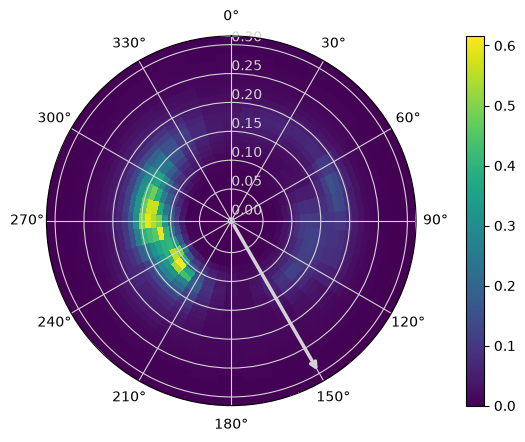

In [75]:
# Source - https://stackoverflow.com/a/36513481
# Posted by Reblochon Masque, modified by community. See post 'Timeline' for change history
# Retrieved 2026-07-01, License - CC BY-SA 4.0

import matplotlib.pyplot as plt
import numpy as np

# pick a sample
sample_id = 14

# chart properties
wav_sample = json.loads(contestant_dataset['Wave directional spectrum'].iloc[sample_id])

direction_resolution = int(wav_sample["DirectionResolution"])
frequency_start = int(wav_sample["FrequencyStart"])
frequency_count = wav_sample["FrequencyCount"]
frequency_resolution = wav_sample["FrequencyResolution"]
frequency_end = frequency_start + (frequency_count - 1) * frequency_resolution

fig = plt.figure()

rad_line = np.linspace(frequency_start, frequency_end, frequency_count)

rad = rad_line
azm = np.linspace(0, 350 * 2 * np.pi / 360, 36)
r, th = np.meshgrid(rad, azm)

# Main dataset
z = np.array(wav_sample["Data"])

# Create polar axes and keep reference
ax = plt.subplot(projection="polar")

# Plot using the axes
ax.plot(azm, r, color='k', ls='none')

c = ax.pcolormesh(th, r, z, cmap='viridis')
plt.colorbar(c, pad=0.1)

# Make angles clockwise
ax.set_theta_direction(-1)

# Set 0 degrees to the top
ax.set_theta_zero_location('N')

# Add an arrow to indicate vessel heading
rmax = ax.get_rmax()

ax.annotate(
    "",
    xy=(np.deg2rad(wav_sample["Heading"]), 0.95 * rmax),
    xytext=(np.deg2rad(wav_sample["Heading"]), 0),
    arrowprops=dict(
        arrowstyle="->",
        color="lightgray",
        lw=2.5
    )
)

# Grids
grid_color = 'lightgray'
ax.grid(color=grid_color)

ax.set_rlabel_position(0)
ax.set_thetagrids([theta * (3 * direction_resolution) for theta in range(360 // (3 * direction_resolution))])

ax.set_rticks(np.linspace(frequency_start, frequency_end - 0.01, 7))
ax.tick_params(axis='y', colors=grid_color)

plt.show()